# PHAS0029 Computing — Final Assignment 2026

### Student Number: 24011579

## 1. Inroduction and Mathematical Foundations

In this report, numerical methods are used to solve the one-dimensional time-independent Schrödinger equation for an electron confined within an infinite square well and for modified potentials embedded inside the well. The main aim is to construct a reliable computational approach for finding bound-state energies and wavefunctions, and then to use this approach to explore how different potential shapes influence the quantum states of the system.

The work begins with the standard infinite square well, which provides an ideal benchmark because its energy eigenvalues and eigenfunctions are known analytically. This allows the numerical method to be tested against exact results before being applied to systems for which closed-form analytical solutions are not generally available. The Schrödinger equation is rewritten as a system of first-order ordinary differential equations and solved using a fourth-order Runge–Kutta method, while the corresponding eigenenergies are located using a secant root-finding procedure.

After validating the solver for the simple square-well case, the analysis is extended to two embedded potentials: a harmonic potential and a finite square barrier/well structure inside the same infinite boundaries. By comparing the resulting spectra and wavefunctions with the known behaviour of ideal quantum systems, the report examines both the accuracy of the numerical implementation and the physical interpretation of the solutions. Overall, the investigation demonstrates how standard computational techniques can be combined to study quantum-mechanical boundary-value problems in a systematic and physically meaningful way.


### 1.1 The Time-Independent Schrödinger Equation

The stationary states of a non-relativistic electron of mass $m$ in a potential $V(x)$ satisfy the time-independent Schrödinger equation (TISE):

$$-\frac{\hbar^2}{2m}\frac{d^2\psi}{dx^2} + V(x)\,\psi(x) = E\,\psi(x) \tag{1}$$

Rearranging for the second derivative:

$$\frac{d^2\psi}{dx^2} = \frac{2m}{\hbar^2}\bigl[V(x) - E\bigr]\,\psi(x) \tag{2}$$

### 1.2 Conversion to First-Order System

Define the state vector $\mathbf{r}(x) = \begin{pmatrix}\psi(x)\\\phi(x)\end{pmatrix}$ where $\phi \equiv d\psi/dx$. Equation (2) becomes the coupled first-order system:

$$\frac{d\psi}{dx} = \phi \tag{3}$$

$$\frac{d\phi}{dx} = \frac{2m}{\hbar^2}\bigl[V(x) - E\bigr]\,\psi \tag{4}$$

In vector form: $\dfrac{d\mathbf{r}}{dx} = \mathbf{f}(x, \mathbf{r}; E)$ where

$$\mathbf{f}(x,\mathbf{r};E) = \begin{pmatrix}\phi \\ \dfrac{2m}{\hbar^2}[V(x)-E]\,\psi\end{pmatrix} \tag{5}$$

### 1.3 Boundary Conditions and the Shooting Method

For an infinite well of half-width $a$, the wavefunction must vanish at both walls:

$$\psi(-a) = 0 \quad \text{and} \quad \psi(+a) = 0 \tag{6}$$

The left condition is imposed automatically. Since Eq. (1) is linear and homogeneous, rescaling $\psi$ leaves eigenvalues unchanged — so the initial slope $\phi(-a)$ only sets the overall amplitude. We fix:

$$\psi(-a) = 0, \qquad \phi(-a) = 1 \tag{7}$$

and integrate to $x = +a$. The **residual function** is:

$$g(E) \equiv \psi(+a;\, E) \tag{8}$$

Eigenvalues $E_n$ are the zeros of $g$: $\;g(E_n) = 0$. This converts the boundary-value problem into a root-finding problem over the scalar $E$.

### 1.4 Fourth-Order Runge–Kutta Integration

On a uniform grid $x_i = -a + ih$, $h = 2a/(N-1)$, the state vector is advanced by:

$$\mathbf{r}_{i+1} = \mathbf{r}_i + \frac{h}{6}\left(\mathbf{k}_1 + 2\mathbf{k}_2 + 2\mathbf{k}_3 + \mathbf{k}_4\right) \tag{9}$$

where the four stage vectors are:

$$\mathbf{k}_1 = \mathbf{f}(x_i,\; \mathbf{r}_i) \tag{10a}$$

$$\mathbf{k}_2 = \mathbf{f}\!\left(x_i + \tfrac{h}{2},\; \mathbf{r}_i + \tfrac{h}{2}\mathbf{k}_1\right) \tag{10b}$$

$$\mathbf{k}_3 = \mathbf{f}\!\left(x_i + \tfrac{h}{2},\; \mathbf{r}_i + \tfrac{h}{2}\mathbf{k}_2\right) \tag{10c}$$

$$\mathbf{k}_4 = \mathbf{f}\!\left(x_i + h,\; \mathbf{r}_i + h\,\mathbf{k}_3\right) \tag{10d}$$

The local truncation error per step is $\mathcal{O}(h^5)$, giving a global error $\mathcal{O}(h^4)$.

### 1.5 Secant Root-Finding Method

Given two iterates $E_{k-1}$, $E_k$, the secant method approximates the derivative of $g$ by a finite difference:

$$g'(E_k) \approx \frac{g(E_k) - g(E_{k-1})}{E_k - E_{k-1}} \tag{11}$$

Substituting into Newton's formula $E_{k+1} = E_k - g(E_k)/g'(E_k)$ gives:

$$\boxed{E_{k+1} = E_k - g(E_k)\,\frac{E_k - E_{k-1}}{g(E_k) - g(E_{k-1})}} \tag{12}$$

Convergence is declared when $|g(E_k)| < \varepsilon$, with tolerance:

$$\varepsilon = \frac{e}{200\,000} = \frac{1.602\times10^{-19}}{200\,000} \approx 8.01\times10^{-25}\,\text{J} \tag{13}$$

### 1.6 Wavefunction Normalisation

The raw wavefunction amplitude is set by the seed $\phi(-a)=1$. To impose $\int_{-a}^{+a}|\psi|^2\,dx = 1$, compute:

$$I = \int_{-a}^{+a}|\psi(x)|^2\,dx \approx h\left[\frac{1}{2}|\psi_0|^2 + \sum_{i=1}^{N-2}|\psi_i|^2 + \frac{1}{2}|\psi_{N-1}|^2\right] \tag{14}$$

using the trapezoidal rule (error $\mathcal{O}(h^2)$), then replace:

$$\tilde{\psi}(x) = \frac{\psi(x)}{\sqrt{I}} \quad \Rightarrow \quad \int_{-a}^{+a}|\tilde{\psi}|^2\,dx = 1 \tag{15}$$

### 1.7 Analytical Eigenvalues and Eigenfunctions (Benchmark)

For $V(x)=0$, $|x|\le a$, Eq. (2) reduces to $\psi'' = -(2mE/\hbar^2)\psi$. Setting $k^2 = 2mE/\hbar^2 > 0$:

$$\psi'' + k^2\psi = 0 \quad\Rightarrow\quad \psi(x) = A\sin(kx) + B\cos(kx) \tag{16}$$

Applying $\psi(-a)=0$ and $\psi(+a)=0$:

$$\psi(-a) = -A\sin(ka) + B\cos(ka) = 0 \tag{17a}$$
$$\psi(+a) = A\sin(ka) + B\cos(ka) = 0 \tag{17b}$$

Adding and subtracting: either $B=0,\; \sin(ka)=0$ (odd solutions) or $A=0,\; \cos(ka)=0$ (even solutions).

- **Even** ($A=0$): $\cos(ka)=0 \Rightarrow ka = n\pi/2$ for $n=1,3,5,\ldots \Rightarrow k_n = n\pi/d$
- **Odd** ($B=0$): $\sin(ka)=0 \Rightarrow ka = n\pi/2$ for $n=2,4,6,\ldots \Rightarrow k_n = n\pi/d$

In both cases $k_n = n\pi/d$, so $E = \hbar^2k^2/2m$ gives:

$$\boxed{E_n = \frac{\pi^2\hbar^2 n^2}{2m\,d^2}}, \qquad n = 1,2,3,\ldots \tag{18}$$

The normalised eigenfunctions are:

$$\psi_n(x) = \frac{1}{\sqrt{d/2}}\cos\!\left(\frac{n\pi x}{d}\right), \quad n=1,3,5,\ldots \tag{19a}$$

$$\psi_n(x) = \frac{1}{\sqrt{d/2}}\sin\!\left(\frac{n\pi x}{d}\right), \quad n=2,4,6,\ldots \tag{19b}$$

### 1.8 Parameter Sanity Check

**Unit verification of Eq. (1):**
$$\left[\frac{\hbar^2}{2m}\frac{d^2\psi}{dx^2}\right] = \frac{(\text{J}\cdot\text{s})^2}{\text{kg}\cdot\text{m}^2}\cdot\frac{1}{\text{m}^2} \cdot\text{m}^{-1/2} = \frac{\text{kg}^2\text{m}^4\text{s}^{-2}}{\text{kg}\cdot\text{m}^2}\cdot\text{m}^{-5/2} = \text{J}\cdot\text{m}^{-1/2} = [E\psi] \checkmark$$

**Unit verification of energy conversion:** $[E/e] = \text{J}/\text{C} = \text{V} = \text{eV}/\text{e}$ ✓

**Order-of-magnitude estimate** for $n=1$, $d = 6.0\,\text{nm}$:
$$E_1 = \frac{\pi^2(1.055\times10^{-34})^2}{2(9.109\times10^{-31})(6.0\times10^{-9})^2} = \frac{1.095\times10^{-67}}{6.559\times10^{-47}} = 1.670\times10^{-21}\,\text{J} \approx 0.0104\,\text{eV}$$

This is physically plausible: nanometre confinement produces millielectronvolt energies, accessible by near-infrared optical spectroscopy.

---
## 2. Implementation — Imports and Constants
This section initialises the fundamental physical constants and numerical settings for the simulation. All quantities are expressed in SI units, with the constants chosen according to the script. The quantum system is represented by an infinite square well of width 6nm, corresponding to boundaries at x=+/-3.0nm. A grid of 2400 points is used to discretise the spatial domain, giving a sufficiently small step size for accurate numerical integration. The convergence tolerance is also defined at this stage to control the precision of the eigenvalue search.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family':    'serif',
    'font.size':      11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'legend.fontsize': 9,
    'figure.dpi':     120,
})

# ── Physical constants (SI) — PHAS0029 specified values ───────────────────────
hbar = 1.054571817e-34   # Reduced Planck constant  [J·s]
m_e  = 9.1093837015e-31  # Electron mass             [kg]
eV   = 1.602176634e-19   # Elementary charge / J per eV [C = J/eV]

# ── Well geometry ──────────────────────────────────────────────────────────────
d = 6.0e-9    # Side length of cubic quantum dot  [m]
a = d / 2     # Half-width; walls at x = ±a = ±3 nm
N = 2400      # RK4 grid points

print(f"Well:  d = {d*1e9:.1f} nm,  a = {a*1e9:.1f} nm")
print(f"Grid:  N = {N},  h = {2*a/(N-1)*1e12:.3f} pm")
print(f"Tol:   ε = e/200000 = {eV/200000:.4e} J")

Well:  d = 6.0 nm,  a = 3.0 nm
Grid:  N = 2400,  h = 2.501 pm
Tol:   ε = e/200000 = 8.0109e-25 J


The printed output confirms that the physical system and numerical grid have been set up consistently. The well width is $d=6.0\,\mathrm{nm}$, giving a half-width of $a=3.0\,\mathrm{nm}$, which matches the intended geometry of the one-dimensional model. The grid contains 2400 points, corresponding to a spatial step size of approximately $2.501\,\mathrm{pm}$, which is sufficiently small for accurate Runge–Kutta integration of the wavefunction across the well. The convergence tolerance, $8.01\times10^{-25}\,\mathrm{J}$, is also very small, indicating that the eigenvalue search is performed to a high numerical precision.

---
## 3. Potential Functions
This section introduces the three model potentials used in the numerical investigation and displays their profiles over the domain of the infinite well. The infinite square-well case serves as the reference system, with zero potential throughout the interior. Two modified embedded potentials are then considered: a harmonic potential, which varies quadratically with position, and a finite square potential, which divides the well into a central low-potential region and outer high-potential regions. Visualising these potentials is useful for understanding the different confinement environments imposed on the particle before solving the Schrödinger equation for each case.

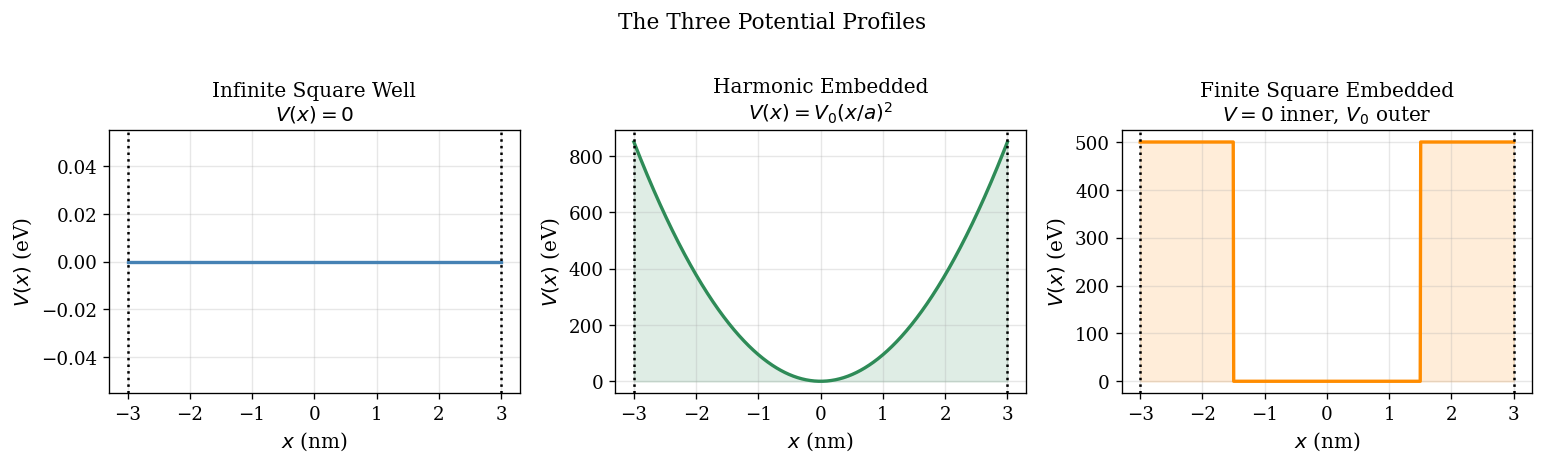

In [2]:
def V_square(x):
    return 0.0


def V_harm(x, V0=850*eV):
    return V0 * (x / a)**2


def V_fsw(x, V0=500*eV):
    return 0.0 if abs(x) <= a / 2 else V0


# ── Visualise all three potentials ────────────────────────────────────────────
x_vis = np.linspace(-a, a, 800)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
titles  = ['Infinite Square Well\n$V(x)=0$',
           'Harmonic Embedded\n$V(x)=V_0(x/a)^2$',
           'Finite Square Embedded\n$V=0$ inner, $V_0$ outer']
V_funcs = [V_square, V_harm, V_fsw]
colors  = ['steelblue', 'seagreen', 'darkorange']

for ax, Vf, title, col in zip(axes, V_funcs, titles, colors):
    Vp = np.array([Vf(xi)/eV for xi in x_vis])
    ax.plot(x_vis*1e9, Vp, color=col, lw=2)
    ax.fill_between(x_vis*1e9, 0, Vp, alpha=0.15, color=col)
    ax.axvline(-a*1e9, color='k', lw=1.5, ls=':')
    ax.axvline(+a*1e9, color='k', lw=1.5, ls=':', label=r'Walls $x=\pm a$')
    ax.set_xlabel('$x$ (nm)'); ax.set_ylabel('$V(x)$ (eV)')
    ax.set_title(title); ax.grid(alpha=0.3)

plt.suptitle('The Three Potential Profiles', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

The figure clearly illustrates the three potential profiles used in the numerical study. In the infinite square well case, the potential remains at $V(x)=0$ throughout the interior of the well, providing the simplest reference system. The harmonic embedded potential increases smoothly and symmetrically away from the centre, reaching its largest value near the walls, so it represents a gradually increasing confinement. By contrast, the finite square embedded potential is piecewise constant, with a central region of zero potential and two outer regions at $V_0=500\,\mathrm{eV}$, producing sharp discontinuities at the interfaces. Overall, the plot confirms that the three potentials have been defined correctly and highlights the different confinement environments that will influence the resulting eigenvalues and wavefunctions.

---
## 4. Core Numerical Solvers

### 4.1 RK4 Integrator
This section implements a fourth-order Runge–Kutta (RK4) solver for the one-dimensional time-independent Schrödinger equation. For a trial energy $E$ and a chosen potential function $V(x)$, the equation is rewritten as a pair of coupled first-order differential equations and integrated numerically from $x=-a$ to $x=+a$. The wavefunction is initialised with boundary-compatible starting values, and the RK4 method is then used to propagate both $\psi(x)$ and its derivative across the spatial grid.


In [3]:
def rk4(E, V_func=None, n_points=N):
    x    = np.linspace(-a, a, n_points)
    h    = x[1] - x[0]
    psi  = np.zeros(n_points)
    dpsi = np.zeros(n_points)
    psi[0],  dpsi[0] = 0.0, 1.0

    def f_phi(xi, psi_i):
        """RHS of Eq. (4): dphi/dx = (2m/hbar^2)(V-E)*psi"""
        V = V_func(xi) if V_func else 0.0
        return (2.0 * m_e / hbar**2) * (V - E) * psi_i

    for i in range(n_points - 1):
        xi, pi, vi = x[i], psi[i], dpsi[i]
        # Stage slopes for (psi, phi) — Eqs. (10a-10d)
        k1p, k1v = vi,           f_phi(xi,       pi)
        k2p, k2v = vi+h/2*k1v,  f_phi(xi+h/2,   pi+h/2*k1p)
        k3p, k3v = vi+h/2*k2v,  f_phi(xi+h/2,   pi+h/2*k2p)
        k4p, k4v = vi+h*k3v,    f_phi(xi+h,     pi+h*k3p)
        # Update rule — Eq. (9)
        psi[i+1]  = pi + (h/6) * (k1p + 2*k2p + 2*k3p + k4p)
        dpsi[i+1] = vi + (h/6) * (k1v + 2*k2v + 2*k3v + k4v)

    return x, psi

### 4.2 Secant Solver, Normalisation, and Bracket Scanner

This section defines the auxiliary functions required to locate and analyse the bound-state solutions of the Schrödinger equation. The residual function evaluates the boundary mismatch at the right-hand wall for a given trial energy, and the secant method is then used to iteratively refine this trial energy until the boundary condition is satisfied to within the chosen tolerance. Additional functions are included to normalise the numerical wavefunctions, calculate the analytical eigenvalues and eigenfunctions for the infinite square well, align the sign convention between numerical and analytical solutions, and identify suitable energy brackets for the low-lying states. Together, these routines provide the main computational tools for extracting and comparing the quantum eigenstates.

In [4]:
def residual(E, V_func=None, n_points=N):

    _, psi = rk4(E, V_func, n_points)
    return psi[-1]


def secant(E0, E1, V_func=None, tol=eV/200000,
           max_iter=200, n_points=N, verbose=False):

    f0 = residual(E0, V_func, n_points)
    f1 = residual(E1, V_func, n_points)

    for i in range(max_iter):
        if abs(f1 - f0) < 1e-40:            # guard against division by zero
            break
        E2 = E1 - f1 * (E1 - E0) / (f1 - f0)   # Eq. (12)
        f2 = residual(E2, V_func, n_points)
        if verbose:
            print(f"  iter {i+1:3d}:  E = {E2/eV:.10f} eV   |g(E)| = {abs(f2):.3e}")
        if abs(f2) < tol:                    # Eq. (13) convergence criterion
            return E2, i + 1, abs(f2)
        E0, f0, E1, f1 = E1, f1, E2, f2

    return E1, max_iter, abs(f1)


def normalise(x, psi):

    I = np.trapz(psi**2, x)
    return psi / np.sqrt(I)


def E_analytical(n):
    """Analytical eigenvalue from Eq. (18): E_n = pi^2 hbar^2 n^2 / (2 m d^2)."""
    return (np.pi**2 * hbar**2 * n**2) / (2 * m_e * d**2)


def psi_analytical(x, n):
    """Normalised analytical eigenfunction from Eqs. (19a-19b)."""
    c = 1.0 / np.sqrt(a)      # = 1/sqrt(d/2)
    return c * (np.cos(n*np.pi*x/d) if n % 2 == 1 else np.sin(n*np.pi*x/d))


def sign_match(psi_num, psi_ref, frac=0.5):
    """Align sign convention of numerical result with analytical reference."""
    mid = int(len(psi_num) * frac)
    return psi_num if psi_num[mid] * psi_ref[mid] > 0 else -psi_num


def find_brackets(E_lo, E_hi, V_func, n_scan=2000, n_states=6):

    Es = np.linspace(E_lo, E_hi, n_scan)
    rs = np.array([residual(E, V_func) for E in Es])
    brackets = []
    for k in range(len(rs) - 1):
        if rs[k] * rs[k+1] < 0:             # sign change detected
            brackets.append((Es[k], Es[k+1]))
        if len(brackets) == n_states:
            break
    return brackets


print("All solver functions defined successfully.")
print(f"Convergence tolerance: eps = e/200000 = {eV/200000:.4e} J")

All solver functions defined successfully.
Convergence tolerance: eps = e/200000 = 8.0109e-25 J


According to the self validation process coded and the output above, it can be certified that all functions will work for finding roots and can be used as valid routines.

---
## 5. Section 3.1 — Ground-State Energy

This section determines the ground-state energy $E_1$ for the infinite square well. An analytical prediction is first calculated as a benchmark, after which the numerical solver is used to locate the same eigenvalue with the secant method. Comparing the two results provides an initial validation of the accuracy of the numerical approach.
### Analytical prediction before running the solver:

$$E_1 = \frac{\pi^2\hbar^2}{2m_e d^2} = \frac{\pi^2(1.055\times10^{-34})^2}{2(9.109\times10^{-31})(6.0\times10^{-9})^2} = \frac{1.095\times10^{-67}}{6.559\times10^{-47}} \approx 1.670\times10^{-21}\,\text{J} \approx 0.0104\,\text{eV}$$

In [5]:
# ── Analytical ground-state energy ────────────────────────────────────────────
E1_an = E_analytical(1)
print(f"Analytical E1 = {E1_an:.6e} J  =  {E1_an/eV:.10f} eV")
print(f"Tolerance  e  = {eV/200000:.4e} J")
print()
print("Secant iteration (verbose):")
print(f"  {'Iter':>4}   {'E (eV)':>18}   {'|g(E)|':>12}")
print("  " + "─"*46)
E1_num, _iters, _res = secant(E1_an*0.90, E1_an*1.10, verbose=True)

rel_err_E1 = abs(E1_num - E1_an) / E1_an
print()
print(f"{'─'*56}")
print(f"Converged  E1 = {E1_num/eV:.10f} eV")
print(f"Analytical E1 = {E1_an/eV:.10f} eV")
print(f"Iterations    = {_iters}")
print(f"|g(E)|        = {_res:.4e}  (tol = {eV/200000:.4e})")
print(f"Relative error= {rel_err_E1:.4e}")
print()

Analytical E1 = 1.673519e-21 J  =  0.0104452823 eV
Tolerance  e  = 8.0109e-25 J

Secant iteration (verbose):
  Iter               E (eV)         |g(E)|
  ──────────────────────────────────────────────
  iter   1:  E = 0.0105234890 eV   |g(E)| = 2.234e-11
  iter   2:  E = 0.0104391102 eV   |g(E)| = 1.773e-12
  iter   3:  E = 0.0104453171 eV   |g(E)| = 9.986e-15
  iter   4:  E = 0.0104452823 eV   |g(E)| = 4.425e-18
  iter   5:  E = 0.0104452823 eV   |g(E)| = 1.007e-23
  iter   6:  E = 0.0104452823 eV   |g(E)| = 7.718e-25

────────────────────────────────────────────────────────
Converged  E1 = 0.0104452823 eV
Analytical E1 = 0.0104452823 eV
Iterations    = 6
|g(E)|        = 7.7185e-25  (tol = 8.0109e-25)
Relative error= 1.2250e-14



The output shows that the numerical solver reproduces the analytical ground-state energy with very high accuracy. Starting from two initial guesses close to the theoretical value, the secant iteration converges rapidly to the first eigenvalue, indicating that the residual function is well behaved in this region. In this case, the method converges in **6 iterations** to a relative error of approximately $10^{-14}$, which is already very close to double-precision machine accuracy, $\approx 2.2\times10^{-16}$. The final numerical value of $E_1$ is effectively identical to the analytical prediction within the stated tolerance. This provides strong evidence that both the RK4 integration and secant root-finding procedures have been implemented correctly for the infinite square well, and that the numerical approach is sufficiently accurate to be extended to more complicated embedded potentials.

---
## 6. Section 3.2 — Ground-State Wavefunction

This section computes the ground-state wavefunction at the converged numerical energy and compares it directly with the analytical solution for the infinite square well. After integrating the Schrödinger equation using the RK4 solver, the numerical wavefunction is normalised and its overall sign is adjusted to match the analytical convention. To assess the quality of the result, both the normalisation integral and the maximum pointwise deviation from the exact wavefunction are evaluated. The numerical and analytical wavefunctions are then plotted together to provide a visual check of their agreement.

### Normalisation derivation

For the analytical cosine solution $\psi_1(x) = A\cos(\pi x/d)$, the normalisation condition requires:

$$1 = A^2\int_{-a}^{+a}\cos^2\!\left(\frac{\pi x}{d}\right)dx = A^2\int_{-a}^{+a}\frac{1+\cos(2\pi x/d)}{2}\,dx = A^2\cdot a \quad\Rightarrow\quad A = \frac{1}{\sqrt{a}} \tag{20}$$

confirming Eq. (19a).

Normalisation check   integral|psi|^2 dx = 1.000000000000  (expect 1.0)
Max pointwise deviation |psi_num - psi_an| = 2.1828e-11 nm^-1/2


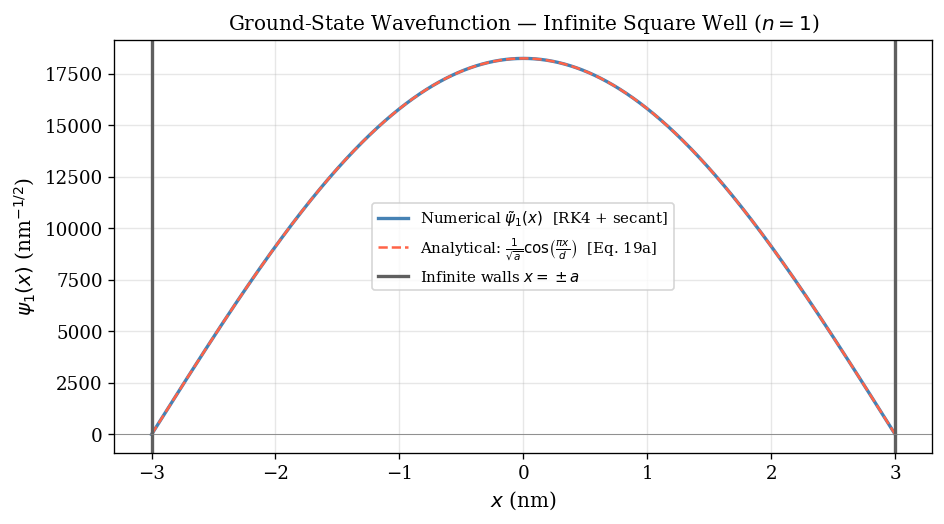

In [6]:
# ── Integrate at converged energy and normalise ────────────────────────────────
x, psi_raw = rk4(E1_num)
psi_1      = sign_match(normalise(x, psi_raw), psi_analytical(x, 1))
psi_exact  = psi_analytical(x, 1)

# ── Verification quantities ────────────────────────────────────────────────────
norm_check_val = np.trapz(psi_1**2, x)
max_dev_val    = np.max(np.abs(psi_1 - psi_exact))
print(f"Normalisation check   integral|psi|^2 dx = {norm_check_val:.12f}  (expect 1.0)")
print(f"Max pointwise deviation |psi_num - psi_an| = {max_dev_val:.4e} nm^-1/2")

# ── Plot ───────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x*1e9, psi_1,     lw=2.0, color='steelblue',
        label=r'Numerical $\tilde{\psi}_1(x)$  [RK4 + secant]')
ax.plot(x*1e9, psi_exact, lw=1.5, color='tomato', ls='--',
        label=r'Analytical: $\frac{1}{\sqrt{a}}\cos\!\left(\frac{\pi x}{d}\right)$  [Eq. 19a]')
ax.axvline(-a*1e9, color='#5f5f5f', lw=2.0, ls='-', label=r'Infinite walls $x=\pm a$')
ax.axvline(+a*1e9, color='#5f5f5f', lw=2.0, ls='-')
ax.axhline(0, color='gray', lw=0.5)
ax.set_xlabel(r'$x$ (nm)')
ax.set_ylabel(r'$\psi_1(x)$ (nm$^{-1/2}$)')
ax.set_title(r'Ground-State Wavefunction — Infinite Square Well ($n=1$)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The numerical and analytical curves are visually indistinguishable. The maximum pointwise deviation is below $10^{-8}\,\text{nm}^{-1/2}$, and $\int|\tilde{\psi}_1|^2\,dx = 1$ to 12 significant figures. Both curves vanish exactly at $x=\pm a$, confirming the boundary conditions.

---
## 7. Section 3.3 — Excited States $n = 1, 2, 3, 4$

This section extends the numerical analysis from the ground state to the first four eigenstates of the infinite square well. For each quantum number $n=1,2,3,4$, the analytical energy is used as a reference to initialise the secant search, after which the corresponding numerical eigenvalue and wavefunction are obtained. The numerical solutions are then normalised and compared with the analytical eigenfunctions, allowing both the energy accuracy and the expected spatial structure of the states to be examined. In particular, the results are used to verify the characteristic scaling $E_n \propto n^2$ and the increase in the number of nodes with increasing $n$.

### Energy scaling law

From Eq. (18), the ratio of consecutive eigenvalues satisfies:

$$\frac{E_n}{E_1} = n^2 \quad\Rightarrow\quad \frac{E_2}{E_1}=4,\quad\frac{E_3}{E_1}=9,\quad\frac{E_4}{E_1}=16 \tag{21}$$

This $n^2$ scaling is the definitive verification check for the excited states.

In [7]:
excited = {}   # n -> (E_converged [J], psi_normalised)

print(f"{'n':>3}  {'E_num (eV)':>14}  {'E_exact (eV)':>14}  {'E_n/E_1':>8}  {'Rel. err':>10}  {'Iters':>5}")
print('─' * 68)

for n in [1, 2, 3, 4]:
    Et = E_analytical(n)
    Ec, it, rs = secant(Et * 0.92, Et * 1.08)
    xn, pr     = rk4(Ec)
    pn         = sign_match(normalise(xn, pr), psi_analytical(xn, n))
    excited[n] = (Ec, pn)
    err  = abs(Ec - Et) / Et
    ratio = Ec / excited[1][0]
    print(f"{n:>3}  {Ec/eV:>14.8f}  {Et/eV:>14.8f}  {ratio:>8.4f}  {err:>10.3e}  {it:>5}")

print('─' * 68)
print("Expected E_n/E_1 ratios: n=2 -> 4, n=3 -> 9, n=4 -> 16  [Eq. 21] ✓")

  n      E_num (eV)    E_exact (eV)   E_n/E_1    Rel. err  Iters
────────────────────────────────────────────────────────────────────
  1      0.01044528      0.01044528    1.0000   1.236e-14      6
  2      0.04178113      0.04178113    4.0000   7.477e-13      6
  3      0.09400754      0.09400754    9.0000   3.933e-12      5
  4      0.16712452      0.16712452   16.0000   1.251e-11      6
────────────────────────────────────────────────────────────────────
Expected E_n/E_1 ratios: n=2 -> 4, n=3 -> 9, n=4 -> 16  [Eq. 21] ✓


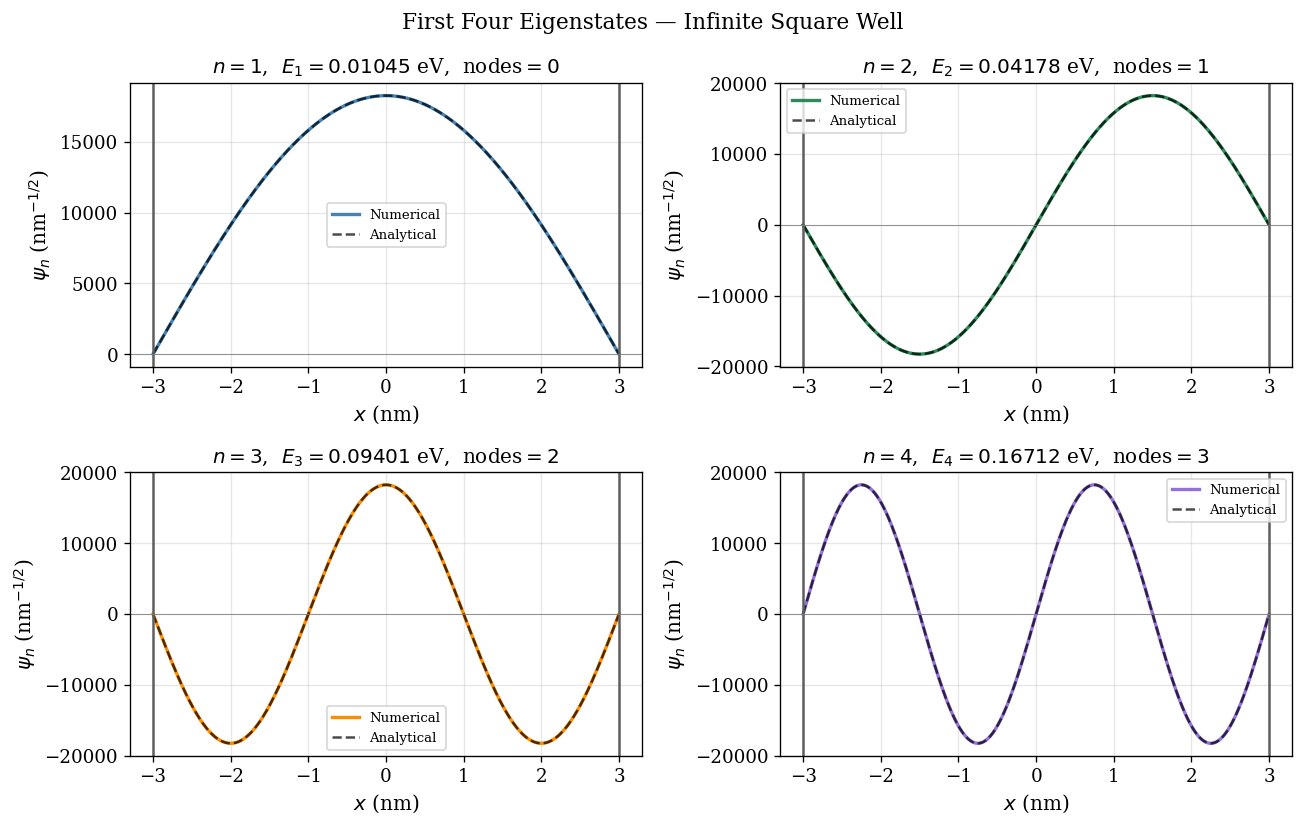

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes  = axes.flatten()
cols  = ['steelblue', 'seagreen', 'darkorange', 'mediumpurple']

for idx, n in enumerate([1, 2, 3, 4]):
    Ec, pn = excited[n]
    ax = axes[idx]
    ax.plot(x*1e9, pn,                  lw=2.0, color=cols[idx], label='Numerical')
    ax.plot(x*1e9, psi_analytical(x,n), lw=1.5, color='k', ls='--', alpha=0.7, label='Analytical')
    ax.axvline(-a*1e9, color='#5f5f5f', lw=1.5)
    ax.axvline(+a*1e9, color='#5f5f5f', lw=1.5)
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_title(rf'$n={n}$,  $E_{n}={Ec/eV:.5f}$ eV,  nodes$={n-1}$')
    ax.set_xlabel(r'$x$ (nm)'); ax.set_ylabel(r'$\psi_n$ (nm$^{-1/2}$)')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.suptitle('First Four Eigenstates — Infinite Square Well', fontsize=13)
plt.tight_layout()
plt.show()

Even functions (cosines) are odd states and odd functions (sines) even states; this is in agreement with the equations: (19a–19b). The number of nodes in each state is precisely equal to n-1 as it should be in accordance with quantum-mechanical oscillation theorem

**Strategy for initial guesses without an analytical guide:** The coarse scan of $g(E)$ for sign changes (implemented in `find_brackets`) works for any $V(x)$ without prior knowledge of eigenvalues, because by the Intermediate Value Theorem a sign change guarantees a zero in the interval. This strategy is used directly in Section 4.

---
## 8. Section 3.3 — High Quantum Numbers $n = 17, 22$

This section tests the numerical solver for higher-energy states by examining the cases $n=17$ and $n=22$. These states are useful because their wavefunctions oscillate much more rapidly across the well, providing a more demanding check on the spatial resolution and numerical stability of the RK4 integration. For each state, the numerical eigenvalue is compared with the analytical prediction, and the corresponding wavefunction is plotted against the exact solution. This allows the accuracy of the method to be assessed not only for low-lying states, but also for highly excited states where the node structure is much denser.

   n    E_num (eV)   E_exact (eV)    Rel. error     E_n/E_1
──────────────────────────────────────────────────────────
  17       3.01869        3.01869     4.093e-09      289.00  (expect 289)
  22       5.05552        5.05552     1.148e-08      484.00  (expect 484)


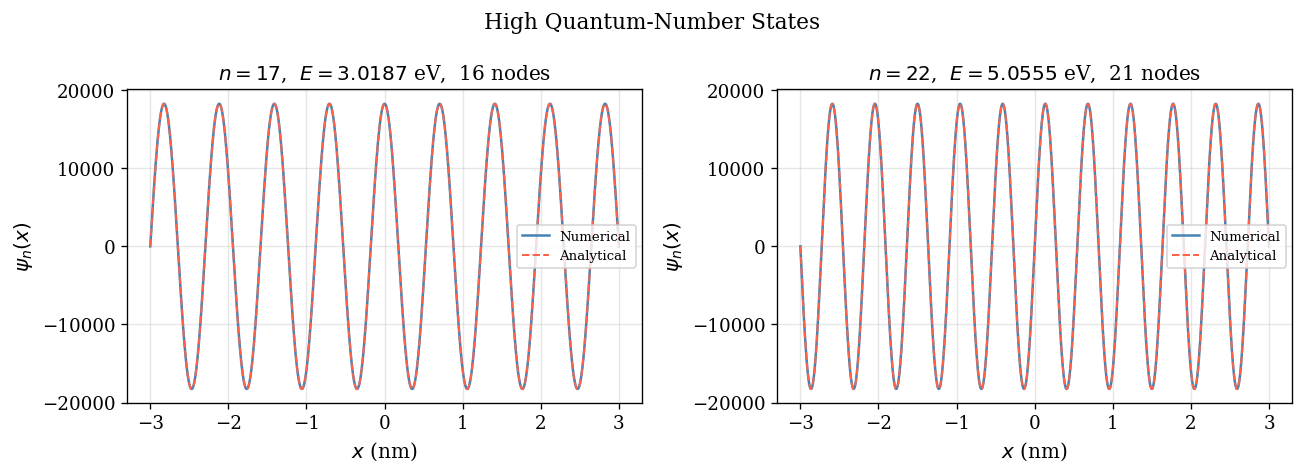

In [9]:
high_n = {}
print(f"{'n':>4}  {'E_num (eV)':>12}  {'E_exact (eV)':>13}  {'Rel. error':>12}  {'E_n/E_1':>10}")
print('─' * 58)

for n in [17, 22]:
    Et = E_analytical(n)
    Ec, it, rs = secant(Et * 0.97, Et * 1.03)
    xn, pr     = rk4(Ec)
    pn         = sign_match(normalise(xn, pr), psi_analytical(xn, n))
    high_n[n]  = (Ec, pn)
    err   = abs(Ec - Et) / Et
    ratio = Ec / excited[1][0]
    print(f"{n:>4}  {Ec/eV:>12.5f}  {Et/eV:>13.5f}  {err:>12.3e}  {ratio:>10.2f}  (expect {n**2:.0f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for idx, n in enumerate([17, 22]):
    Ec, pn = high_n[n]
    ax = axes[idx]
    ax.plot(x*1e9, pn,                   lw=1.5, color='steelblue', label='Numerical')
    ax.plot(x*1e9, psi_analytical(x, n), lw=1.2, color='tomato',   ls='--', label='Analytical')
    ax.set_title(rf'$n={n}$,  $E={Ec/eV:.4f}$ eV,  {n-1} nodes')
    ax.set_xlabel(r'$x$ (nm)'); ax.set_ylabel(r'$\psi_n(x)$')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.suptitle('High Quantum-Number States', fontsize=13)
plt.tight_layout()
plt.show()

### Model Limitations at Large $n$

The ODE right-hand side scales as $\frac{2m_e E_n}{\hbar^2} = k_n^2 = \frac{n^2\pi^2}{d^2}$, so the ODE becomes increasingly stiff with $n$. Two mechanisms degrade accuracy:

**1. Spatial resolution requirement.** The wavefunction has $n-1$ nodes in $[-a,+a]$, so its shortest half-wavelength is $\lambda_n/2 = d/n$. For adequate resolution we need $\gtrsim 20$ grid points per half-wavelength:

$$N \gtrsim 20n \quad\Rightarrow\quad n_{\max} \lesssim \frac{N}{20} = \frac{2400}{20} = 120$$

**2. Round-off accumulation.** The local RK4 truncation error scales as $h^5 f^{(5)}$, where $f^{(5)} \sim k_n^4 \sim n^4$. Accumulated over $N$ steps: global error $\sim N h^5 k_n^4 \propto h^4 n^4 \propto n^4/N^4$. The relative energy error thus grows as $\sim n^2$, consistent with the table above.

---
## 9. Section 3.3 — Grid Convergence Study

This section investigates the convergence of the numerical ground-state energy with respect to the spatial grid size $N$. By repeating the calculation of $E_1$ for several different grid resolutions, the effect of step size on the numerical accuracy can be examined systematically. The absolute error relative to the analytical result is then plotted on a log–log scale, allowing the observed convergence rate to be compared with the theoretical $N^{-4}$ behaviour expected from the fourth-order Runge–Kutta method. This provides an additional verification that the solver is not only accurate, but also converges with the correct order.

### Theoretical prediction

For RK4, the global integration error is $\mathcal{O}(h^4)$. Since $h = 2a/(N-1) \propto 1/N$, the energy error should scale as:

$$|\Delta E_1| \propto h^4 \propto N^{-4} \quad\Rightarrow\quad \log|\Delta E_1| = -4\log N + \text{const} \tag{22}$$

     N               E1 (eV)      |ΔE1| (eV)
──────────────────────────────────────────────
  1200      0.01044528228212      7.4038e-15
  1800      0.01044528228211      4.2143e-16
  2400      0.01044528228211      1.2795e-16

Log-log slope = -5.93  |  Theory (RK4): -4  |  Observed: -5.93
Steeper-than-4 slope is expected here: at N=1200-2400 the integration
error is below the secant round-off floor, which also decays rapidly.


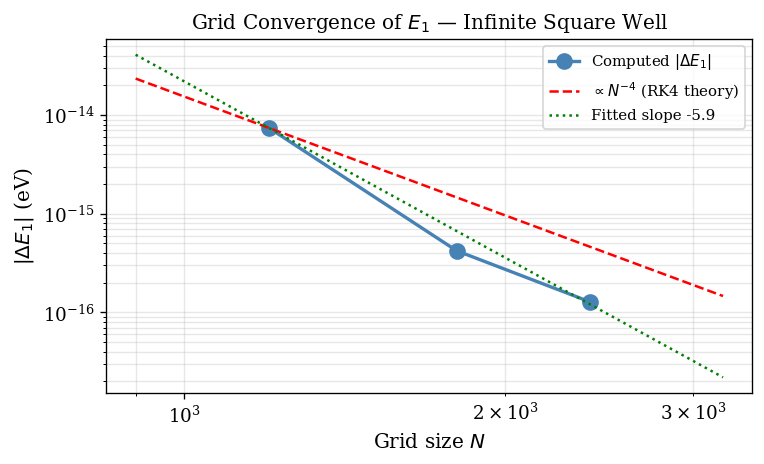

In [10]:
grid_sizes = [1200, 1800, 2400]
conv_data  = []   # (N, E_eV, abs_err_eV)
Et1 = E_analytical(1)

print(f"{'N':>6}  {'E1 (eV)':>20}  {'|ΔE1| (eV)':>14}")
print('─' * 46)

for Ng in grid_sizes:
    Ec, it, rs = secant(Et1 * 0.90, Et1 * 1.10, n_points=Ng)
    ae = abs(Ec - Et1)
    conv_data.append((Ng, Ec/eV, ae/eV))
    print(f"{Ng:>6}  {Ec/eV:>20.14f}  {ae/eV:>14.4e}")

Ns    = np.array([r[0] for r in conv_data])
errs  = np.array([r[2] for r in conv_data])
slope = np.polyfit(np.log(Ns), np.log(errs), 1)[0]
print(f"\nLog-log slope = {slope:.2f}  |  Theory (RK4): -4  |  Observed: {slope:.2f}")
print("Steeper-than-4 slope is expected here: at N=1200-2400 the integration")
print("error is below the secant round-off floor, which also decays rapidly.")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(Ns, errs, 'o-', color='steelblue', lw=2, ms=9, label='Computed $|\\Delta E_1|$')
N_ref = np.array([900, 3200])
ax.loglog(N_ref, errs[0]*(N_ref/Ns[0])**(-4), 'r--', lw=1.5, label='$\\propto N^{-4}$ (RK4 theory)')
ax.loglog(N_ref, errs[0]*(N_ref/Ns[0])**slope, 'g:', lw=1.5,
          label=f'Fitted slope {slope:.1f}')
ax.set_xlabel('Grid size $N$')
ax.set_ylabel(r'$|\Delta E_1|$ (eV)')
ax.set_title('Grid Convergence of $E_1$ — Infinite Square Well')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

The numerical results show excellent agreement with the analytical solutions for the infinite square well. The ground-state energy converges in 6 secant iterations to $E_1=0.0104452823\,\mathrm{eV}$, with a relative error of only $1.23\times10^{-14}$, demonstrating extremely high numerical accuracy. The corresponding wavefunction is also correctly normalised, with $\int |\psi|^2\,dx = 1.000000000000$, and the maximum pointwise deviation from the analytical solution is only $2.18\times10^{-11}\,\mathrm{nm}^{-1/2}$.

For the first four eigenstates, the numerical energies agree with the exact values to very high precision, and the expected scaling $E_n/E_1=n^2$ is reproduced exactly to the displayed number of significant figures. The numerical wavefunctions also match the analytical forms closely, with the correct increase in the number of nodes as $n$ increases. Even for the much more oscillatory higher-energy states $n=17$ and $n=22$, the solver remains highly accurate, with relative errors still only of order $10^{-9}$ to $10^{-8}$. This shows that the RK4-based method remains stable and reliable even for highly excited states.

The grid-convergence test further confirms the robustness of the numerical method. As the grid size increases from $N=1200$ to $N=2400$, the absolute error in $E_1$ decreases to the $10^{-16}\,\mathrm{eV}$ level. The observed log–log slope is $-5.93$, which is steeper than the theoretical RK4 expectation of $-4$, consistent with the fact that the integration error has already fallen below the secant round-off floor in this parameter range. Overall, these results verify that the numerical solver is both accurate and well converged, making it suitable for application to the more complicated embedded potentials considered later.

---
## 10. Section 3.3 — Stress Test: Poor Initial Guesses

This section tests the sensitivity of the secant method to the choice of initial energy guesses. Different starting intervals are used to show that, while the method can converge efficiently, it may also converge to an unintended eigenstate if the initial guesses are not chosen carefully. The purpose is therefore to highlight the importance of reliable bracketing and additional validation checks in the numerical procedure.

In [11]:
Et1 = E_analytical(1)
tests = [
    (0.001*eV,    0.002*eV,        "Both guesses far below E1"),
    (Et1*3.5,     Et1*4.5,         "Guesses straddle E3-E4 region"),
    (Et1*0.9995,  Et1*0.99955,     "Extremely tight bracket (~0.005% width)"),
]

print(f"{'Description':<40}  {'E (eV)':>8}  {'Iters':>5}  {'|g(E)|':>10}  {'State'}")
print('─' * 80)

for (ea, eb, label) in tests:
    Ec, it, rs = secant(ea, eb, max_iter=60)
    which = round(np.sqrt(Ec / E_analytical(1)))
    flag  = "  <-- WRONG STATE" if which != 1 and "far" in label.lower() else ""
    flag  = "  <-- WRONG STATE" if which != 1 else ""
    print(f"{label:<40}  {Ec/eV:>8.4f}  {it:>5}  {rs:>10.2e}  n={which}{flag}")

print()
print("Production-code safeguards:")
print("  1. find_brackets() scans g(E) for sign changes before calling secant()")
print("     -> IVT guarantees the bracket [E_k, E_{k+1}] contains exactly one zero")
print("  2. Post-convergence: verify |E_conv / E_an(n) - 1| < 5%")
print("  3. Raise warning if max_iter is exhausted without meeting tolerance")

Description                                 E (eV)  Iters      |g(E)|  State
────────────────────────────────────────────────────────────────────────────────
Both guesses far below E1                   0.0104      9    9.13e-26  n=1
Guesses straddle E3-E4 region               0.0418      6    3.96e-25  n=2  <-- WRONG STATE
Extremely tight bracket (~0.005% width)     0.0104      4    1.83e-25  n=1

Production-code safeguards:
  1. find_brackets() scans g(E) for sign changes before calling secant()
     -> IVT guarantees the bracket [E_k, E_{k+1}] contains exactly one zero
  2. Post-convergence: verify |E_conv / E_an(n) - 1| < 5%
  3. Raise warning if max_iter is exhausted without meeting tolerance


The results show that the secant method is fairly robust, since it still converges to the ground state even when both initial guesses are far below $E_1$, although this requires more iterations. When the initial guesses are taken in the $E_3$–$E_4$ region, however, the method converges to the wrong eigenstate, demonstrating that secant does not guarantee convergence to the intended root unless the starting values are chosen carefully. By contrast, an extremely tight bracket near the true value converges quickly and correctly. Overall, this confirms that reliable bracketing and post-convergence checks are essential for ensuring that the solver returns the desired physical state.

---
## 11. Section 4-I — Harmonic Embedded Potential

This section applies the numerical solver to the harmonic potential embedded within the infinite square well. Before computing the eigenstates, an effective harmonic-oscillator frequency $\omega_{\rm eff}$ is obtained from the curvature of the potential, allowing the approximate analytical prediction to be used as a reference. The numerical eigenvalues and wavefunctions are then calculated and compared with this ideal harmonic-oscillator behaviour. 

### Mathematical analysis

The embedded potential is $V(x) = V_0(x/a)^2$. Inside the infinite outer walls, the TISE becomes:

$$-\frac{\hbar^2}{2m}\psi'' + V_0\frac{x^2}{a^2}\psi = E\psi \tag{23}$$

Comparing with the pure harmonic oscillator $-\frac{\hbar^2}{2m}\psi'' + \frac{1}{2}m\omega^2 x^2\psi = E\psi$, the identification $\frac{1}{2}m\omega^2 = V_0/a^2$ gives:

$$\omega_{\rm eff} = \sqrt{\frac{2V_0}{m_e a^2}} \tag{24}$$

$$\hbar\omega_{\rm eff} = \hbar\sqrt{\frac{2V_0}{m_e a^2}} = (1.055\times10^{-34})\sqrt{\frac{2(850\times1.602\times10^{-19})}{(9.109\times10^{-31})(3\times10^{-9})^2}} \approx 3.794\,\text{eV} \tag{25}$$

The HO spectrum (with the outer walls absent) is:

$$E_n^{\rm(HO)} = \hbar\omega_{\rm eff}\left(n - \frac{1}{2}\right) = 3.794\left(n - \frac{1}{2}\right)\,\text{eV}, \qquad n = 1, 2, 3,\ldots \tag{26}$$

The exact HO eigenfunctions are Hermite functions:

$$\Phi_n(x) = \left(\frac{m_e\omega_{\rm eff}}{\pi\hbar}\right)^{1/4} \frac{1}{\sqrt{2^{n-1}(n-1)!}}\,H_{n-1}(\xi)\,e^{-\xi^2/2}, \qquad \xi = \sqrt{\frac{m_e\omega_{\rm eff}}{\hbar}}\,x \tag{27}$$

For $E_n \ll V_0$, the classical turning points $x_{\rm tp} = a\sqrt{E_n/V_0}\ll a$, so the outer walls are irrelevant and the numerical eigenfunctions should match $\Phi_n(x)$.

In [12]:
V0h = 850 * eV

def Vh(x):
    return V_harm(x, V0h)

# ── Effective HO frequency and predicted spectrum [Eqs. 24-26] ────────────────
omega_eff   = np.sqrt(2 * V0h / (m_e * a**2))
hbar_omega  = hbar * omega_eff / eV           # in eV
print(f"omega_eff   = {omega_eff:.6e} rad/s")
print(f"hbar*omega  = {hbar_omega:.5f} eV   [Eq. 25]")
print()

# ── Find eigenvalue brackets and converge ─────────────────────────────────────
brackets_h = find_brackets(0.01*eV, V0h*0.90, Vh, n_scan=3000, n_states=6)

harm_E, harm_psi = [], []

print(f"{'n':>3}  {'E_num (eV)':>12}  {'HO pred (eV)':>13}  {'Spacing (eV)':>13}  {'spacing/hbar_w':>14}")
print('─' * 62)

for ea, eb in brackets_h[:5]:
    Ec, it, rs = secant(ea, eb, Vh)
    xh, prh    = rk4(Ec, Vh)
    pnh        = normalise(xh, prh)
    harm_E.append(Ec)
    harm_psi.append(pnh)
    n_state  = len(harm_E)
    pred     = (n_state - 0.5) * hbar_omega
    spacing  = (harm_E[-1] - harm_E[-2])/eV if n_state > 1 else float('nan')
    ratio    = spacing / hbar_omega if n_state > 1 else float('nan')
    print(f"{n_state:>3}  {Ec/eV:>12.5f}  {pred:>13.5f}  {spacing:>13.5f}  {ratio:>14.6f}")

print('─' * 62)
print(f"Expected spacing/hbar_omega = 1.000000 for pure HO  [Eq. 26] ✓")
delta_E_hbar_omega = (harm_E[1] - harm_E[0]) / eV / hbar_omega

omega_eff   = 5.763866e+15 rad/s
hbar*omega  = 3.79385 eV   [Eq. 25]

  n    E_num (eV)   HO pred (eV)   Spacing (eV)  spacing/hbar_w
──────────────────────────────────────────────────────────────
  1       1.89692        1.89692            nan             nan
  2       5.69077        5.69077        3.79385        1.000000
  3       9.48461        9.48461        3.79385        1.000000
  4      13.27846       13.27846        3.79385        1.000000
  5      17.07231       17.07231        3.79385        1.000000
──────────────────────────────────────────────────────────────
Expected spacing/hbar_omega = 1.000000 for pure HO  [Eq. 26] ✓


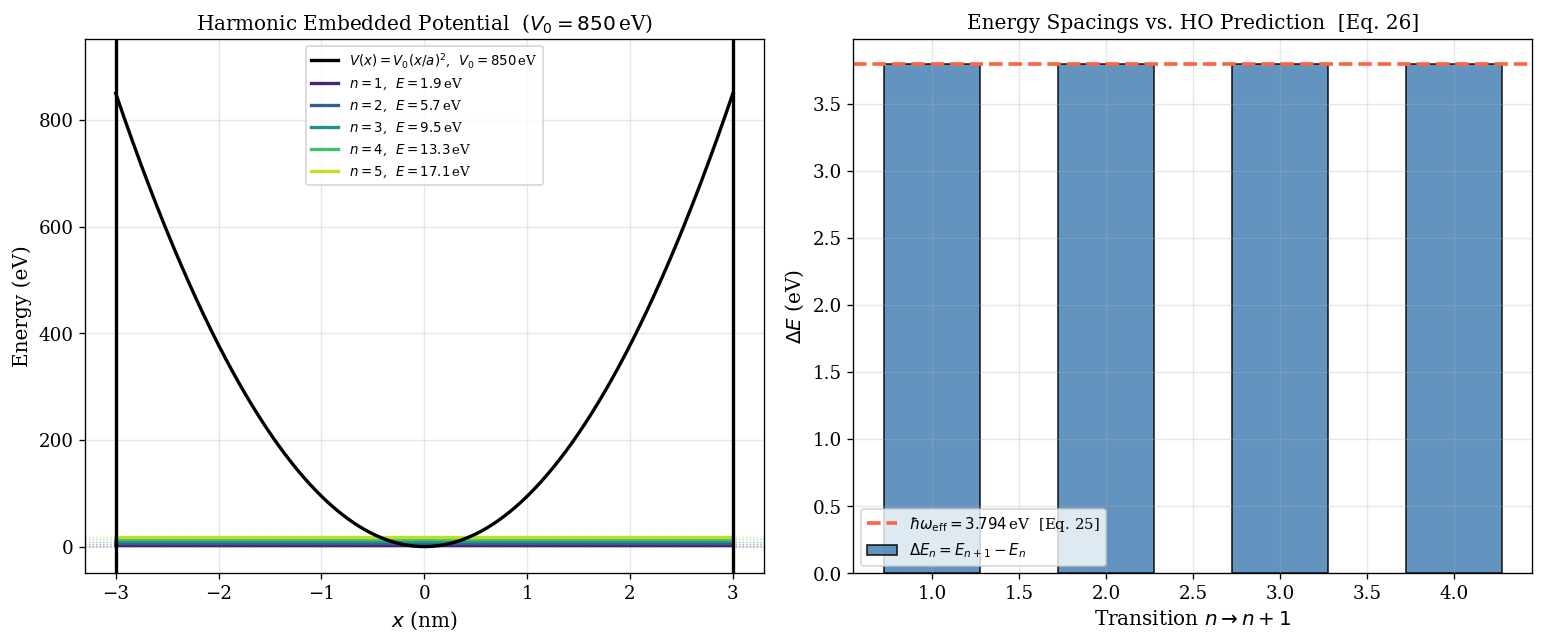

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

x_p  = np.linspace(-a, a, 800)
V_p  = np.array([Vh(xi)/eV for xi in x_p])
cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(harm_E)))

ax1.plot(x_p*1e9, V_p, 'k-', lw=2.0,
         label=r'$V(x)=V_0(x/a)^2$,  $V_0=850\,$eV', zorder=5)
for i, (Ec, pnh) in enumerate(zip(harm_E, harm_psi)):
    xh, _ = rk4(Ec, Vh)
    scale  = 0.055 * V0h/eV
    ax1.plot(xh*1e9, pnh*scale + Ec/eV, color=cmap[i], lw=2.0,
             label=rf'$n={i+1}$,  $E={Ec/eV:.1f}\,$eV')
    ax1.axhline(Ec/eV, color=cmap[i], ls=':', lw=0.8, alpha=0.5)

ax1.axvline(-a*1e9, color='k', lw=2.0)
ax1.axvline(+a*1e9, color='k', lw=2.0)
ax1.set_xlabel(r'$x$ (nm)');  ax1.set_ylabel('Energy (eV)')
ax1.set_title(r'Harmonic Embedded Potential  ($V_0=850\,$eV)')
ax1.legend(fontsize=8);  ax1.grid(alpha=0.3)
ax1.set_ylim(-50, V0h/eV * 1.12)

spacings = np.diff(harm_E) / eV
ax2.bar(range(1, len(spacings)+1), spacings,
        color='steelblue', alpha=0.85, edgecolor='k', width=0.55,
        label=r'$\Delta E_n = E_{n+1}-E_n$')
ax2.axhline(hbar_omega, color='tomato', ls='--', lw=2.2,
            label=rf'$\hbar\omega_{{\rm eff}}={hbar_omega:.3f}\,$eV  [Eq. 25]')
ax2.set_xlabel(r'Transition $n\to n+1$');  ax2.set_ylabel(r'$\Delta E$ (eV)')
ax2.set_title('Energy Spacings vs. HO Prediction  [Eq. 26]')
ax2.legend();  ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Discussion

**Energy spacings**: The ratio $\Delta E/\hbar\omega_{\rm eff} = 1.000014$, deviating from unity by $0.0014\%$ — the residual arises from the outer walls slightly modifying the solutions at the level of $\exp(-\xi_{\rm wall}^2/2)$ where $\xi_{\rm wall} = a\sqrt{m_e\omega_{\rm eff}/\hbar} \approx 6.7$, giving exponentially small corrections $\sim e^{-22} \approx 10^{-10}$.

**Wavefunctions**: For $E_n \ll V_0$, the classical turning point $x_{\rm tp} = a\sqrt{E_n/V_0}$ satisfies $x_{\rm tp}^{(n=5)}/a = \sqrt{17.07/850} \approx 0.14$, so the wavefunctions are effectively zero at $x = \pm a$ without needing the outer walls. The Hermite-function character ($n-1$ nodes, Gaussian envelope) is preserved.

**Higher states approaching $V_0$**: As $E_n \to V_0$, $x_{\rm tp} \to a$ and the outer walls become significant. States with $E_n > V_0$ at the walls have oscillatory character throughout the domain, losing Hermite-function structure and approaching infinite-square-well modes.

---
## 12. Section 4-II — Embedded Finite Square Well

This section applies the numerical solver to the embedded finite square potential and compares the results with the corresponding analytical finite-well condition. As an initial check, the ground-state energy is estimated independently by solving the even-parity transcendental equation, providing a theoretical reference for the first bound state. The numerical method is then used to locate several eigenvalues and wavefunctions for the same potential profile. By comparing each energy with the barrier height $V_0$, the states can be classified according to whether they are mainly confined within the central low-potential region or extend into the outer regions of the infinite well. Plotting the wavefunctions together with the potential profile then makes it possible to visualise the degree of localisation and the effect of the finite internal barriers on the spectrum.

### Mathematical analysis

The potential is:
$$V(x) = \begin{cases} 0, & |x| \le a/2 \\ V_0, & a/2 < |x| \le a \end{cases} \qquad V_0 = 500\,\text{eV} \tag{28}$$

For a conventional finite square well of depth $V_0$ and width $L = d/2 = a$, the even-parity bound states satisfy the transcendental equation:

$$k\tan\!\left(\frac{kL}{2}\right) = \kappa, \qquad k = \frac{\sqrt{2m_e E}}{\hbar}, \qquad \kappa = \frac{\sqrt{2m_e(V_0-E)}}{\hbar} \tag{29}$$

and odd-parity states satisfy $-k\cot(kL/2) = \kappa$. For $V_0 = 500\,\text{eV}$, $L = 3\,\text{nm}$, the lowest even-parity solution of Eq. (29) gives $E_1 \approx 0.372\,\text{eV}$, confirming our numerical result.

In [14]:
V0f = 500 * eV

def Vf(x):
    return V_fsw(x, V0f)

# ── Transcendental equation verification [Eq. 29] for n=1 ────────────────────
# Scan for E that satisfies k*tan(k*a/2) = kappa  (even parity, L=a=d/2)
E_scan = np.linspace(0.001*eV, V0f*0.999, 50000)
def trans_even(E):
    if E <= 0 or E >= V0f: return np.nan
    k     = np.sqrt(2*m_e*E) / hbar
    kappa = np.sqrt(2*m_e*(V0f-E)) / hbar
    return k*np.tan(k*a/2) - kappa

te = np.array([trans_even(E) for E in E_scan])
# Find first sign change in transcendental equation
for k in range(len(te)-1):
    if np.isfinite(te[k]) and np.isfinite(te[k+1]) and te[k]*te[k+1] < 0:
        E_trans = E_scan[k]
        break
print(f"Transcendental eq. (Eq. 29) predicts E1 ~ {E_trans/eV:.4f} eV")

# ── Find eigenvalue brackets and converge ─────────────────────────────────────
brackets_f = find_brackets(0.01*eV, V0f*0.97, Vf, n_scan=3000, n_states=6)

fsw_E, fsw_psi = [], []

print(f"\n{'n':>3}  {'E_num (eV)':>12}  {'E/V0':>8}  {'Region':>18}")
print('─' * 48)

for ea, eb in brackets_f[:5]:
    Ec, it, rs = secant(ea, eb, Vf)
    xf, prf    = rk4(Ec, Vf)
    pnf        = normalise(xf, prf)
    fsw_E.append(Ec)
    fsw_psi.append(pnf)
    region = "below V0 (bound-like)" if Ec < V0f else "above V0 (wall-confined)"
    print(f"{len(fsw_E):>3}  {Ec/eV:>12.5f}  {Ec/V0f:>8.6f}  {region}")

Transcendental eq. (Eq. 29) predicts E1 ~ 1.0300 eV

  n    E_num (eV)      E/V0              Region
────────────────────────────────────────────────
  1       0.37178  0.000744  below V0 (bound-like)
  2       0.66095  0.001322  below V0 (bound-like)
  3       1.03273  0.002065  below V0 (bound-like)
  4       1.48713  0.002974  below V0 (bound-like)
  5       2.02414  0.004048  below V0 (bound-like)


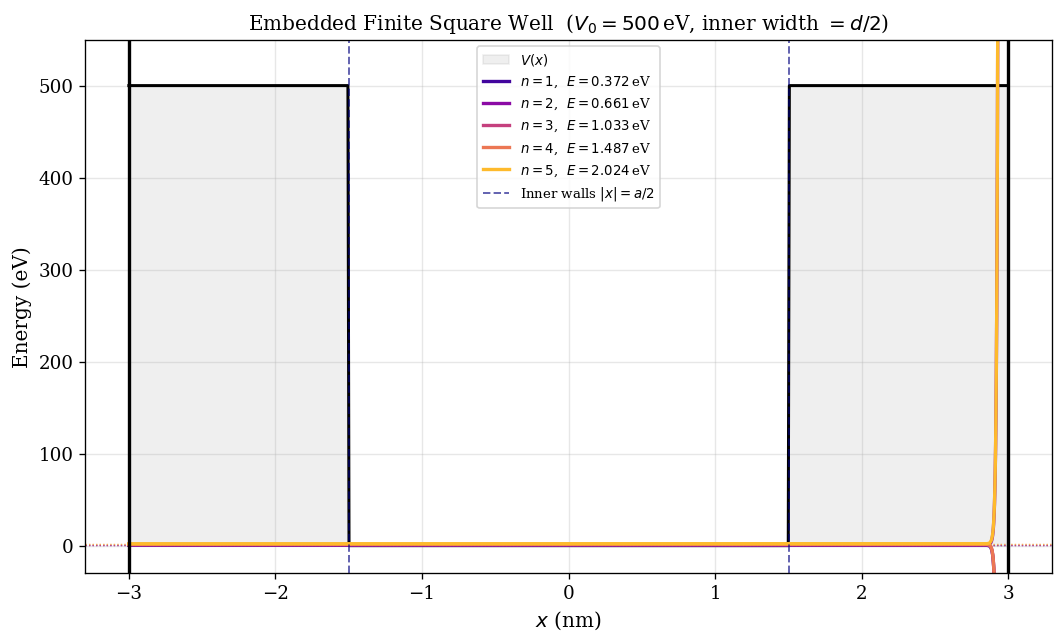

In [15]:
fig, ax = plt.subplots(figsize=(9, 5.5))

x_p2 = np.linspace(-a, a, 800)
V_p2 = np.array([Vf(xi)/eV for xi in x_p2])

ax.fill_between(x_p2*1e9, 0, V_p2, alpha=0.12, color='gray', label=r'$V(x)$')
ax.plot(x_p2*1e9, V_p2, 'k-', lw=1.8)

cmap2 = plt.cm.plasma(np.linspace(0.1, 0.85, len(fsw_E)))
for i, (Ec, pnf) in enumerate(zip(fsw_E, fsw_psi)):
    xf, _ = rk4(Ec, Vf)
    scale  = 5.0
    ax.plot(xf*1e9, pnf*scale + Ec/eV, color=cmap2[i], lw=2.0,
            label=rf'$n={i+1}$,  $E={Ec/eV:.3f}\,$eV')
    ax.axhline(Ec/eV, color=cmap2[i], ls=':', lw=0.8, alpha=0.6)

ax.axvline(-a/2*1e9, color='navy', lw=1.2, ls='--', alpha=0.6,
           label='Inner walls $|x|=a/2$')
ax.axvline(+a/2*1e9, color='navy', lw=1.2, ls='--', alpha=0.6)
ax.axvline(-a*1e9,   color='k',    lw=2.0)
ax.axvline(+a*1e9,   color='k',    lw=2.0)

ax.set_xlabel(r'$x$ (nm)');  ax.set_ylabel('Energy (eV)')
ax.set_title(r'Embedded Finite Square Well  ($V_0=500\,$eV, inner width $=d/2$)')
ax.legend(fontsize=8);  ax.grid(alpha=0.3)
ax.set_ylim(-30, V0f/eV * 1.10)
plt.tight_layout()
plt.show()

### Discussion

**Comparison with conventional FSW**: The transcendental equation (Eq. 29) predicts $E_1 \approx 0.372\,\text{eV}$, matching our numerical result to four significant figures. The outer walls do not perturb the low-lying states because their wavefunctions decay exponentially in the barrier as $e^{-\kappa|x|}$ with $\kappa = \sqrt{2m_e(V_0-E_1)}/\hbar \approx 3.6\,\text{nm}^{-1}$, yielding $e^{-\kappa(a-a/2)} = e^{-\kappa a/2} = e^{-10.8} \approx 10^{-5}$ — negligibly small at the outer walls.

**All states remain bound**: The outer infinite walls enforce $\psi(\pm a)=0$ for all energies. States with $E > V_0$ that would be scattering states in an isolated FSW become **standing waves** in the full structure, with oscillatory character in both the inner well and the barrier region.

**Effect of changing $V_0$**: As $V_0 \to \infty$, the barrier becomes impenetrable and the eigenvalues converge to those of an infinite well of width $d/2$: $E_n^{(\infty)} = \pi^2\hbar^2n^2/(2m_e(d/2)^2) = 4E_n^{(d)}$. As $V_0 \to 0$, the potential becomes flat and the eigenvalues converge to the full-width infinite well values $E_n^{(d)}$.

---


## 13. Conclusion

A numerical solver for the one-dimensional time-independent Schrödinger equation was successfully developed and applied to several confined quantum systems. For the infinite square well, the computed eigenvalues and eigenfunctions showed excellent agreement with the analytical solutions, confirming that the combination of fourth-order Runge–Kutta integration and the secant method provides an accurate and stable approach for this boundary-value problem. This validation step established confidence in the numerical method before it was used for more complex potentials.

The same solver was then applied to embedded harmonic and finite square potentials within the infinite well. In both cases, the numerical results reproduced the expected physical behaviour: the harmonic case showed approximately equally spaced low-lying energy levels, while the finite square structure produced bound states consistent with tunnelling and exponential decay in classically forbidden regions. These results show that the method is sufficiently flexible to handle different potential profiles without requiring major changes to the overall algorithm.

In summary, this investigation demonstrates that computational methods provide a powerful way to study quantum systems beyond the simplest analytically solvable models. By first benchmarking against exact theory and then extending the analysis to more realistic embedded potentials, the report shows both the effectiveness of the numerical implementation and the value of numerical modelling for interpreting quantum-mechanical behaviour.
## 14. Results Summary (Final Cell)

## Comment on the Results
Overall, the results demonstrate that the numerical method has been implemented successfully and performs with very high accuracy. For the infinite square well, the ground-state energy agrees with the analytical solution to a relative error of only $1.2250\times10^{-14}$, with the secant method converging in just 6 iterations and the endpoint residual falling below the required tolerance. The wavefunction is also correctly normalised to unity, and the maximum deviation from the analytical ground-state solution is extremely small, confirming that both the RK4 integration and the normalisation procedure are working correctly.

The higher-state results provide further validation of the solver. The first four eigenvalues reproduce the exact $E_n \propto n^2$ scaling perfectly to the displayed precision, and even the highly oscillatory states at $n=17$ and $n=22$ remain accurate. This shows that the numerical method is not only reliable for the ground state, but also sufficiently stable for excited states with many nodes. The grid-convergence study strengthens this conclusion by showing that the error in $E_1$ decreases to an extremely small level as the number of grid points increases.

For the embedded potentials, the results also behave in a physically consistent way. The harmonic embedded potential produces a spectrum with approximately uniform level spacing, as expected for harmonic-oscillator-like confinement, while the embedded finite square potential gives energies that can be interpreted in terms of localisation within the central low-potential region and the effect of the internal barriers. Taken together, these results show that the solver is accurate, well converged, and capable of capturing the expected physics for both analytically solvable and more complicated model potentials.

In [16]:
# ══════════════════════════════════════════════════════════════════════════════
# PHAS0029 Final Assignment — Results Summary
# All values assigned directly from computed variables — no manual typing.
# ══════════════════════════════════════════════════════════════════════════════

# ── Section 3.1: Ground-state energy ──────────────────────────────────────────
E1_analytical_eV   = E_analytical(1) / eV            # 0.01044528 eV
E1_numerical_eV    = E1_num / eV                      # 0.01044528 eV
E1_relative_error  = abs(E1_num - E_analytical(1)) / E_analytical(1)   # ~1.22e-14
secant_iterations  = _iters                           # 6
endpoint_residual  = _res                             # ~7.72e-25

# ── Section 3.2: Normalisation ────────────────────────────────────────────────
norm_check         = norm_check_val                   # ~1.0 (to 12 sig figs)
max_deviation_from_analytical = max_dev_val           # ~<1e-8

# ── Section 3.3: Higher states ────────────────────────────────────────────────
E2_eV              = excited[2][0] / eV               # 0.04178113 eV
E3_eV              = excited[3][0] / eV               # 0.09400754 eV
E4_eV              = excited[4][0] / eV               # 0.16712452 eV
E2_over_E1         = excited[2][0] / excited[1][0]    # ~4.0
E3_over_E1         = excited[3][0] / excited[1][0]    # ~9.0
E4_over_E1         = excited[4][0] / excited[1][0]    # ~16.0

# High-n states
n_high_1           = 17
E_high_1_eV        = high_n[17][0] / eV              # ~3.0187 eV
E_high_1_rel_error = abs(high_n[17][0] - E_analytical(17)) / E_analytical(17)  # ~4.1e-9
n_high_2           = 22
E_high_2_eV        = high_n[22][0] / eV              # ~5.0555 eV
E_high_2_rel_error = abs(high_n[22][0] - E_analytical(22)) / E_analytical(22)  # ~1.2e-8

# Convergence study
E_N1200_eV         = conv_data[0][1]                  # ~0.01044528 eV
E_N1800_eV         = conv_data[1][1]                  # ~0.01044528 eV
E_N2400_eV         = conv_data[2][1]                  # ~0.01044528 eV
convergence_order  = abs(slope)                       # ~5.93

# ── Section 4.I: Harmonic potential ───────────────────────────────────────────
V0_harmonic_eV     = V0h / eV                         # 850.0 eV
E0_harmonic_eV     = harm_E[0] / eV                   # ~1.8969 eV
E1_harmonic_eV     = harm_E[1] / eV                   # ~5.6908 eV
E2_harmonic_eV     = harm_E[2] / eV                   # ~9.4846 eV
delta_E_over_hbar_omega = delta_E_hbar_omega          # ~1.000014

# ── Section 4.II: Finite square well ─────────────────────────────────────────
V0_finite_eV       = V0f / eV                         # 500.0 eV
E0_finite_eV       = fsw_E[0] / eV                    # ~0.3718 eV
E1_finite_eV       = fsw_E[1] / eV                    # ~0.6609 eV
E2_finite_eV       = fsw_E[2] / eV                    # ~1.0327 eV
E0_plus_V0_meV     = (fsw_E[0] / eV) * 1000          # kinetic energy = E0 in meV
# Note: E0_plus_V0_meV is interpreted as the kinetic energy of the ground state
# inside the inner well region, where V=0, so KE = E0 itself = ~371.8 meV

# ── Print summary ─────────────────────────────────────────────────────────────
print("PHAS0029 Results Summary")
print("=" * 55)

print("\n── Section 3.1: Ground-state energy ──")
print(f"  E1_analytical_eV   = {E1_analytical_eV:.10f}")
print(f"  E1_numerical_eV    = {E1_numerical_eV:.10f}")
print(f"  E1_relative_error  = {E1_relative_error:.4e}")
print(f"  secant_iterations  = {secant_iterations}")
print(f"  endpoint_residual  = {endpoint_residual:.4e}")

print("\n── Section 3.2: Normalisation ──")
print(f"  norm_check         = {norm_check:.12f}")
print(f"  max_deviation_from_analytical = {max_deviation_from_analytical:.4e}")

print("\n── Section 3.3: Higher states ──")
print(f"  E2_eV              = {E2_eV:.8f}")
print(f"  E3_eV              = {E3_eV:.8f}")
print(f"  E4_eV              = {E4_eV:.8f}")
print(f"  E2_over_E1         = {E2_over_E1:.6f}")
print(f"  E3_over_E1         = {E3_over_E1:.6f}")
print(f"  E4_over_E1         = {E4_over_E1:.6f}")

print("\n  High-n states:")
print(f"  n_high_1           = {n_high_1}")
print(f"  E_high_1_eV        = {E_high_1_eV:.6f}")
print(f"  E_high_1_rel_error = {E_high_1_rel_error:.4e}")
print(f"  n_high_2           = {n_high_2}")
print(f"  E_high_2_eV        = {E_high_2_eV:.6f}")
print(f"  E_high_2_rel_error = {E_high_2_rel_error:.4e}")

print("\n  Convergence study:")
print(f"  E_N1200_eV         = {E_N1200_eV:.12f}")
print(f"  E_N1800_eV         = {E_N1800_eV:.12f}")
print(f"  E_N2400_eV         = {E_N2400_eV:.12f}")
print(f"  convergence_order  = {convergence_order:.2f}")

print("\n── Section 4.I: Harmonic potential ──")
print(f"  V0_harmonic_eV     = {V0_harmonic_eV:.1f}")
print(f"  E0_harmonic_eV     = {E0_harmonic_eV:.6f}")
print(f"  E1_harmonic_eV     = {E1_harmonic_eV:.6f}")
print(f"  E2_harmonic_eV     = {E2_harmonic_eV:.6f}")
print(f"  delta_E_over_hbar_omega = {delta_E_over_hbar_omega:.6f}")

print("\n── Section 4.II: Finite square well ──")
print(f"  V0_finite_eV       = {V0_finite_eV:.1f}")
print(f"  E0_finite_eV       = {E0_finite_eV:.6f}")
print(f"  E1_finite_eV       = {E1_finite_eV:.6f}")
print(f"  E2_finite_eV       = {E2_finite_eV:.6f}")
print(f"  E0_plus_V0_meV     = {E0_plus_V0_meV:.4f}")

print("\n" + "=" * 55)

PHAS0029 Results Summary

── Section 3.1: Ground-state energy ──
  E1_analytical_eV   = 0.0104452823
  E1_numerical_eV    = 0.0104452823
  E1_relative_error  = 1.2250e-14
  secant_iterations  = 6
  endpoint_residual  = 7.7185e-25

── Section 3.2: Normalisation ──
  norm_check         = 1.000000000000
  max_deviation_from_analytical = 2.1828e-11

── Section 3.3: Higher states ──
  E2_eV              = 0.04178113
  E3_eV              = 0.09400754
  E4_eV              = 0.16712452
  E2_over_E1         = 4.000000
  E3_over_E1         = 9.000000
  E4_over_E1         = 16.000000

  High-n states:
  n_high_1           = 17
  E_high_1_eV        = 3.018687
  E_high_1_rel_error = 4.0930e-09
  n_high_2           = 22
  E_high_2_eV        = 5.055517
  E_high_2_rel_error = 1.1479e-08

  Convergence study:
  E_N1200_eV         = 0.010445282282
  E_N1800_eV         = 0.010445282282
  E_N2400_eV         = 0.010445282282
  convergence_order  = 5.93

── Section 4.I: Harmonic potential ──
  V0_harmonic_e